In [28]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [3]:
df=pd.read_csv(r"/Users/drashtidarji/Documents/my projects/Housing Prices Prediction/train.csv")

In [4]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [65]:
missing=df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)
missing

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# Missing Values ka Percentage

In [16]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage = missing_percentage[missing_percentage > 0].sort_values(ascending=False)

display(missing_percentage)

PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageType       5.547945
GarageYrBlt      5.547945
GarageFinish     5.547945
GarageQual       5.547945
GarageCond       5.547945
BsmtExposure     2.602740
BsmtFinType2     2.602740
BsmtQual         2.534247
BsmtCond         2.534247
BsmtFinType1     2.534247
MasVnrArea       0.547945
Electrical       0.068493
dtype: float64

In [ ]:
# Target Variable Analysis(SalePrice)

In [19]:
df['SalePrice'].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

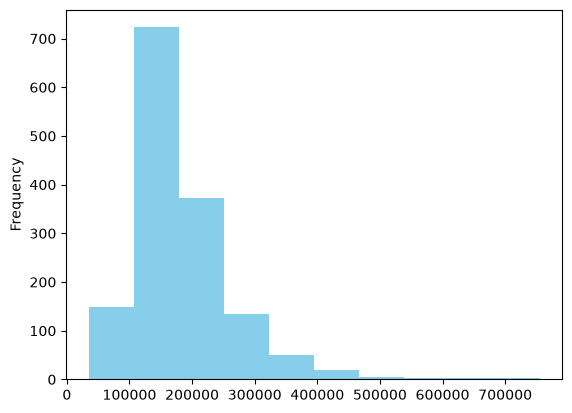

In [24]:
# Histogram

df["SalePrice"].plot(kind="hist",bins=10,edgecolor="none",color='skyblue')
plt.show

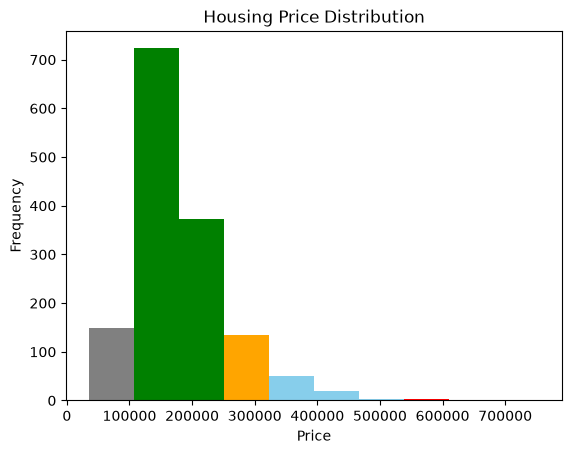

In [26]:
# method 2

# 1. Histogram banayein aur uske bars (patches) aur bins ko save karein
counts, bins, patches = plt.hist(df['SalePrice'], bins=10, edgecolor='none')

# 2. Har bar ki price value (bins) ke hisab se alag color set karein
for i in range(len(patches)):
    price_val = bins[i]  # Bar ki shuruati price
    
    if price_val < 100000:
        patches[i].set_facecolor('gray')       # $100k se kam
    elif 100000 <= price_val < 200000:
        patches[i].set_facecolor('green')      # $100,000 - $200,000 (Sabse zyada houses)
    elif 200000 <= price_val < 300000:
        patches[i].set_facecolor('orange')     # $200,000 - $300,000
    elif 300000 <= price_val < 500000:
        patches[i].set_facecolor('skyblue')    # $300,000 - $500,000
    else:
        patches[i].set_facecolor('red')        # $500,000 se above

plt.title('Housing Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()


In [ ]:
# Boxplot – Outliers Detection

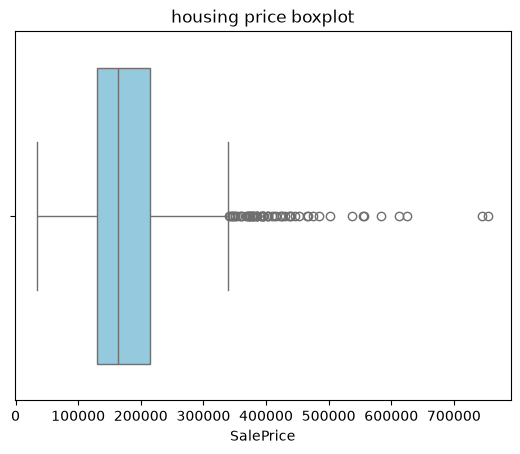

In [31]:
sns.boxplot(x=df["SalePrice"],color="skyblue")
plt.title("housing price boxplot")
plt.show()

In [32]:
# Correlation Analysis

In [33]:
correlation = df["SalePrice"].corr(df["Id"])
print("correlation:",correlation)

correlation: -0.021916719443431112


In [35]:
# numerical columns

numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()["SalePrice"].sort_values(ascending=False)

display(correlation)

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

In [ ]:
# Correlation Heatmap

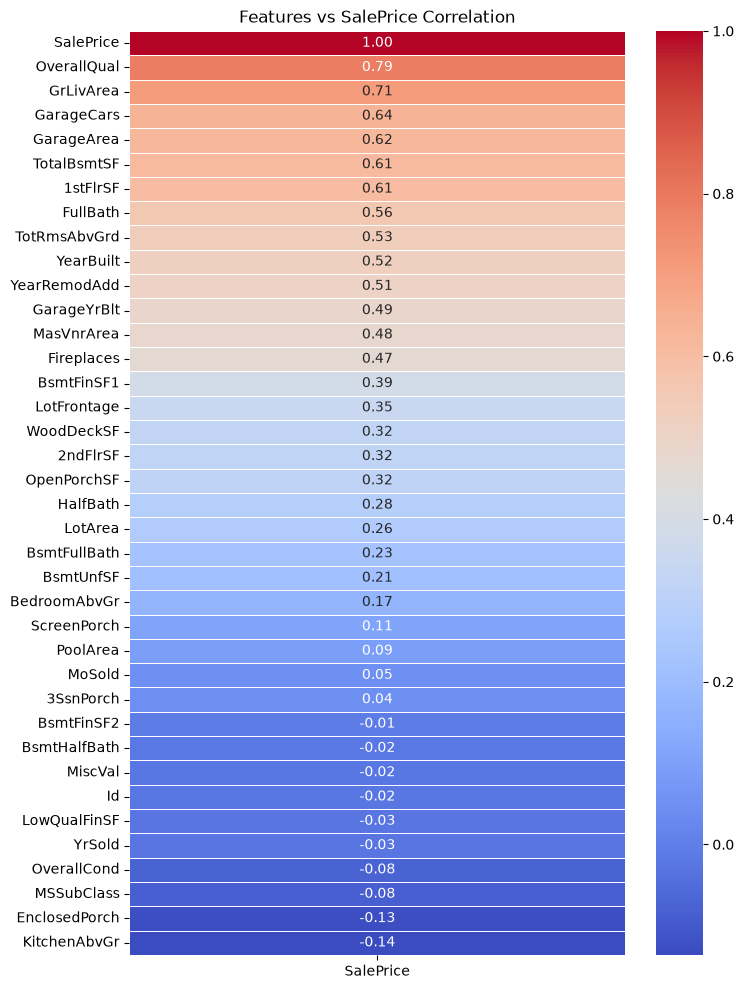

In [44]:
plt.figure(figsize=(8, 12))

correlation = numeric_df.corr()[["SalePrice"]].sort_values(by="SalePrice",ascending=False)

sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f",linewidths=0.5)

plt.title("Features vs SalePrice Correlation")
plt.show()

In [ ]:
# Categorical Features – Neighborhood Analysis

In [46]:
df['Neighborhood'].unique()

<StringArray>
['CollgCr', 'Veenker', 'Crawfor', 'NoRidge', 'Mitchel', 'Somerst',  'NWAmes',
 'OldTown', 'BrkSide',  'Sawyer', 'NridgHt',   'NAmes', 'SawyerW',  'IDOTRR',
 'MeadowV', 'Edwards',  'Timber', 'Gilbert', 'StoneBr', 'ClearCr', 'NPkVill',
 'Blmngtn',  'BrDale',   'SWISU', 'Blueste']
Length: 25, dtype: str

In [50]:
df["Neighborhood"].value_counts()

Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
StoneBr     25
SWISU       25
MeadowV     17
Blmngtn     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64

In [59]:
df.groupby("Neighborhood")['SalePrice'].mean().sort_values(ascending=False).round(2)

Neighborhood
NoRidge    335295.32
NridgHt    316270.62
StoneBr    310499.00
Timber     242247.45
Veenker    238772.73
Somerst    225379.84
ClearCr    212565.43
Crawfor    210624.73
CollgCr    197965.77
Blmngtn    194870.88
Gilbert    192854.51
NWAmes     189050.07
SawyerW    186555.80
Mitchel    156270.12
NAmes      145847.08
NPkVill    142694.44
SWISU      142591.36
Blueste    137500.00
Sawyer     136793.14
OldTown    128225.30
Edwards    128219.70
BrkSide    124834.05
BrDale     104493.75
IDOTRR     100123.78
MeadowV     98576.47
Name: SalePrice, dtype: float64

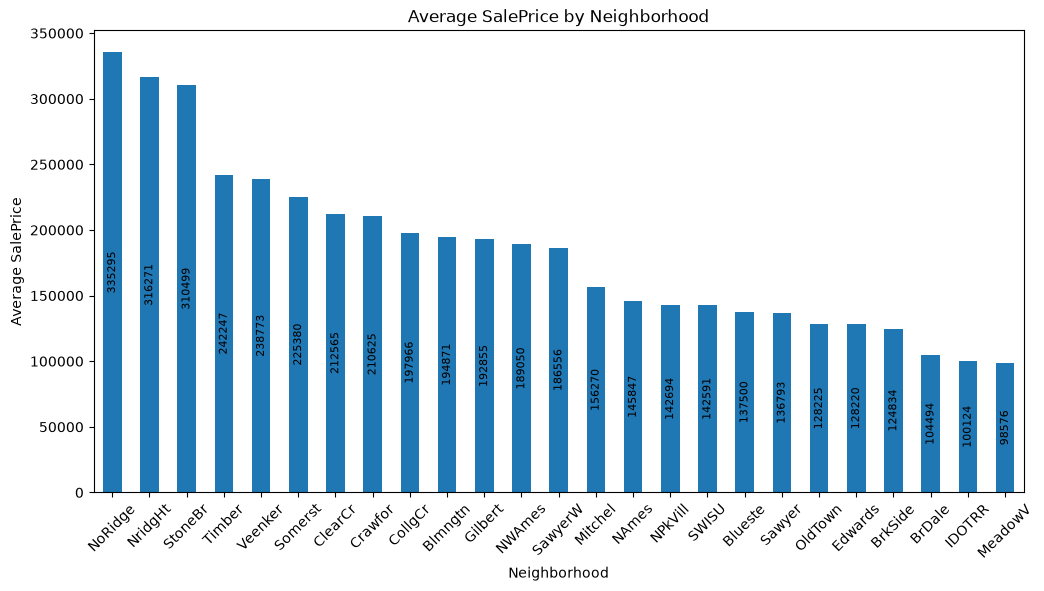

In [70]:
plt.figure(figsize=(12, 6))

ax = neighborhood_price.plot(kind="bar")

plt.title("Average SalePrice by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Average SalePrice")
plt.xticks(rotation=45)

ax.bar_label(ax.containers[0],fmt='%.0f',label_type='center',color='black',fontsize=8, rotation=90)

plt.show()

In [ ]:
# HouseStyle analyze

In [73]:
df["HouseStyle"].unique()

<StringArray>
['2Story', '1Story', '1.5Fin', '1.5Unf', 'SFoyer', 'SLvl', '2.5Unf', '2.5Fin']
Length: 8, dtype: str

In [75]:
df['HouseStyle'].value_counts()

HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64

In [79]:
df.groupby('HouseStyle')['SalePrice'].mean().sort_values(ascending=False).round(2)

HouseStyle
2.5Fin    220000.00
2Story    210051.76
1Story    175985.48
SLvl      166703.38
2.5Unf    157354.55
1.5Fin    143116.74
SFoyer    135074.49
1.5Unf    110150.00
Name: SalePrice, dtype: float64

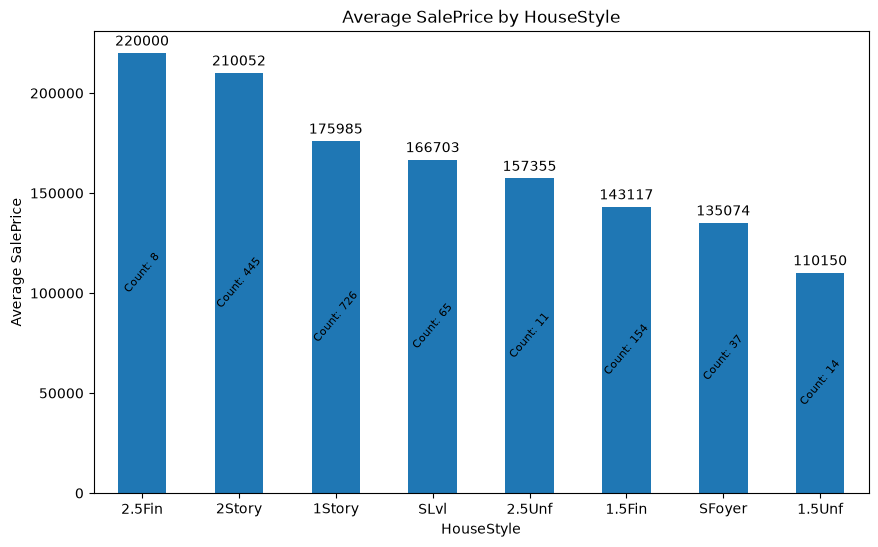

In [98]:
house_price = df.groupby("HouseStyle")["SalePrice"].mean().sort_values(ascending=False)

house_count = df["HouseStyle"].value_counts()

plt.figure(figsize=(10, 6))

ax = house_price.plot(kind="bar")

plt.title("Average SalePrice by HouseStyle")
plt.xlabel("HouseStyle")
plt.ylabel("Average SalePrice")
plt.xticks(rotation=0)

# Average SalePrice above bars
ax.bar_label(ax.containers[0],fmt='%.0f',label_type='edge',color='black',padding=3)

# House count inside bars
for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()
    style = house_price.index[i]
    count = house_count[style]

    ax.text(bar.get_x() + bar.get_width()/2,height/2,f"Count: {count}",ha='center',va='center',rotation=50,color='black',fontsize=8)

plt.show()

In [99]:
# Overallqual analysis

In [102]:
df['OverallQual'].nunique()

10

In [112]:
df["OverallQual"].value_counts().sort_index()

OverallQual
1       2
2       3
3      20
4     116
5     397
6     374
7     319
8     168
9      43
10     18
Name: count, dtype: int64

In [114]:
quality_price = df.groupby("OverallQual")["SalePrice"].mean().round(2)

display(quality_price)

OverallQual
1      50150.00
2      51770.33
3      87473.75
4     108420.66
5     133523.35
6     161603.03
7     207716.42
8     274735.54
9     367513.02
10    438588.39
Name: SalePrice, dtype: float64

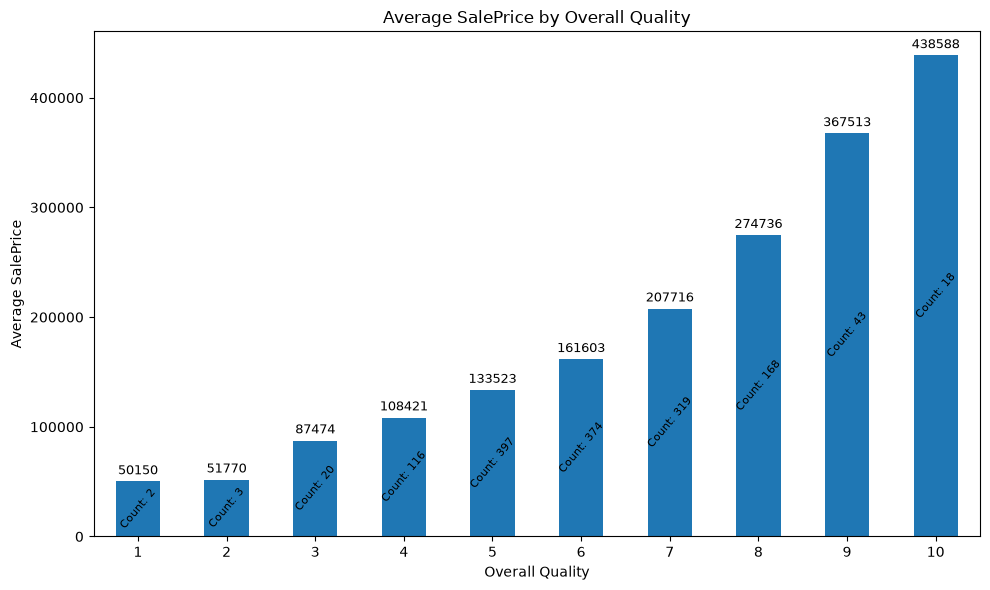

In [116]:
quality_price = df.groupby("OverallQual")["SalePrice"].mean()

quality_count = df["OverallQual"].value_counts().sort_index()

plt.figure(figsize=(10, 6))

ax = quality_price.plot(kind="bar")

plt.title("Average SalePrice by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Average SalePrice")

# Average SalePrice above bars
ax.bar_label(ax.containers[0],fmt='%.0f',label_type='edge',color='black',padding=3,fontsize=9)

# House count inside bars
for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()
    count = quality_count.loc[quality_price.index[i]]

    ax.text(bar.get_x() + bar.get_width()/2,height/2,f"Count: {count}",ha='center',va='center',rotation=50,color='black',fontsize=8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [117]:
# GarageCars 

In [120]:
df['GarageCars'].unique()

array([2, 3, 1, 0, 4])

In [121]:
df['GarageCars'].value_counts().sort_index()

GarageCars
0     81
1    369
2    824
3    181
4      5
Name: count, dtype: int64

In [122]:
df.groupby('GarageCars')['SalePrice'].mean().round(2)

GarageCars
0    103317.28
1    128116.69
2    183851.66
3    309636.12
4    192655.80
Name: SalePrice, dtype: float64

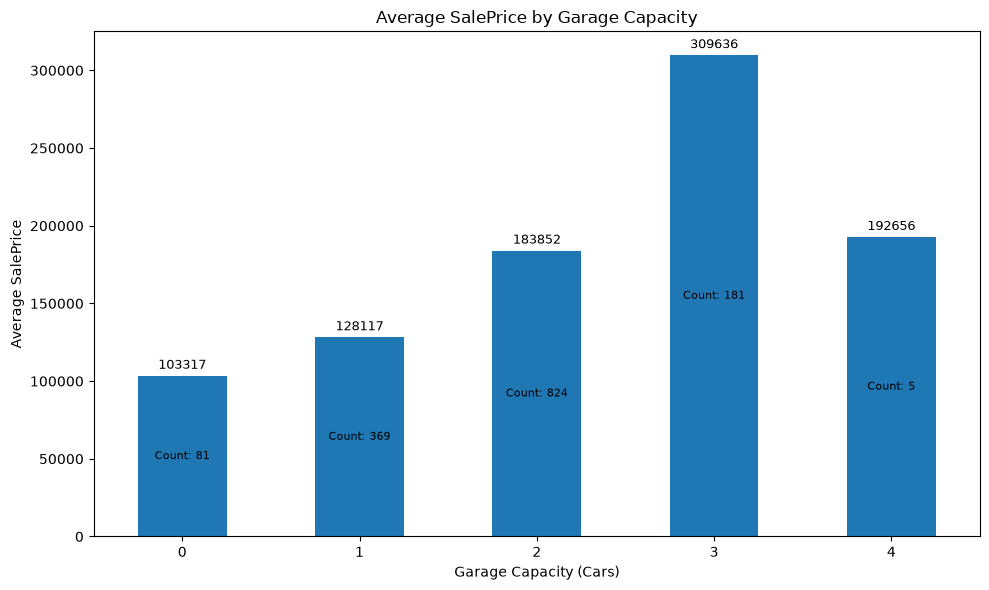

In [125]:
garage_price = df.groupby("GarageCars")["SalePrice"].mean()

garage_count = df["GarageCars"].value_counts().sort_index()

plt.figure(figsize=(10, 6))

ax = garage_price.plot(kind="bar")

plt.title("Average SalePrice by Garage Capacity")
plt.xlabel("Garage Capacity (Cars)")
plt.ylabel("Average SalePrice")

# Average SalePrice above bars
ax.bar_label(ax.containers[0],fmt='%.0f',label_type='edge',color='black',padding=3,fontsize=9)

# House count inside bars
for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()
    count = garage_count.loc[garage_price.index[i]]

    ax.text(bar.get_x() + bar.get_width()/2,height/2,f"Count: {count}",ha='center',va='center',rotation=0,color='black',fontsize=8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
#FullBath

In [126]:
df['FullBath'].unique()

array([2, 1, 3, 0])

In [127]:
df['FullBath'].value_counts().sort_index()

FullBath
0      9
1    650
2    768
3     33
Name: count, dtype: int64

In [129]:
df.groupby("FullBath")["SalePrice"].mean().sort_index().round(2)

FullBath
0    165200.89
1    134751.44
2    213009.83
3    347822.91
Name: SalePrice, dtype: float64

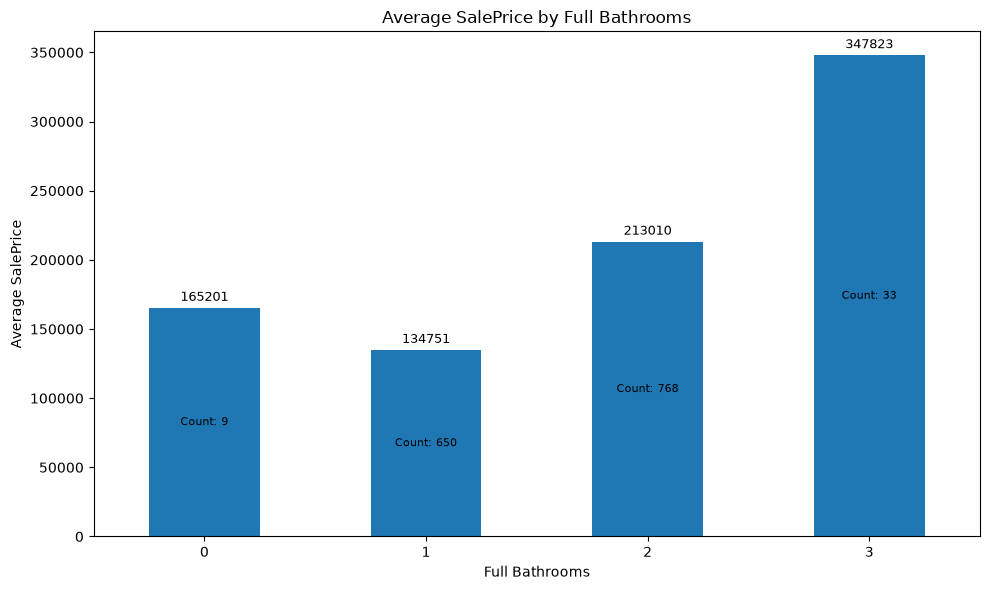

In [132]:
# Average SalePrice for each FullBath category
bath_price = df.groupby("FullBath")["SalePrice"].mean()

# Total houses in each FullBath category
bath_count = df["FullBath"].value_counts().sort_index()

# Create figure
plt.figure(figsize=(10, 6))

# Create bar chart
ax = bath_price.plot(kind="bar")

# Chart title and labels
plt.title("Average SalePrice by Full Bathrooms")
plt.xlabel("Full Bathrooms")
plt.ylabel("Average SalePrice")

# Show average price above each bar
ax.bar_label(ax.containers[0],fmt='%.0f',label_type='edge',color='black',padding=3,fontsize=9)

# Show house count inside each bar
for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()

    count = bath_count.loc[bath_price.index[i]]

    ax.text(bar.get_x() + bar.get_width()/2,height/2,f"Count: {count}",ha='center',va='center',rotation=0,color='black',fontsize=8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# BedroomAbvGr

In [135]:
df['BedroomAbvGr'].unique()

array([3, 4, 1, 2, 0, 5, 6, 8])

In [138]:
df['BedroomAbvGr'].value_counts().sort_index()

BedroomAbvGr
0      6
1     50
2    358
3    804
4    213
5     21
6      7
8      1
Name: count, dtype: int64

In [139]:
df.groupby('BedroomAbvGr')['SalePrice'].mean().sort_index().round(2)

BedroomAbvGr
0    221493.17
1    173162.42
2    158197.66
3    181056.87
4    220421.25
5    180819.05
6    143779.00
8    200000.00
Name: SalePrice, dtype: float64

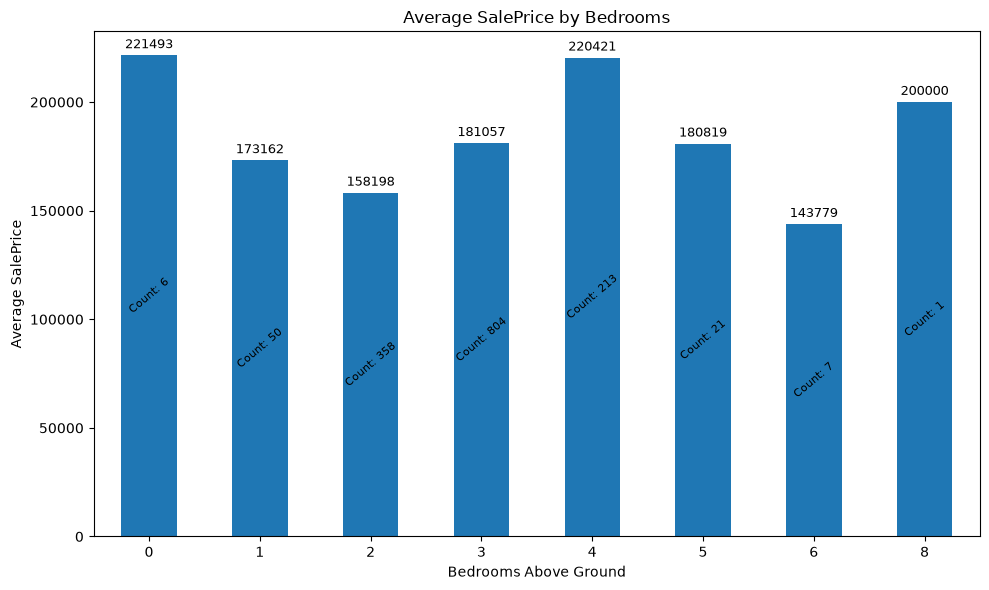

In [144]:
# Average SalePrice for each Bedroom category
bedroom_price = df.groupby("BedroomAbvGr")["SalePrice"].mean()

# Total houses in each Bedroom category
bedroom_count = df["BedroomAbvGr"].value_counts().sort_index()

# Create figure
plt.figure(figsize=(10, 6))

# Create bar chart
ax = bedroom_price.plot(kind="bar")

# Chart title and labels
plt.title("Average SalePrice by Bedrooms")
plt.xlabel("Bedrooms Above Ground")
plt.ylabel("Average SalePrice")

# Show average price above bars
ax.bar_label(ax.containers[0],fmt='%.0f',label_type='edge',color='black',padding=3,fontsize=9)

# Show house count inside bars
for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()

    count = bedroom_count.loc[bedroom_price.index[i]]

    ax.text(bar.get_x() + bar.get_width()/2,height/2,f"Count: {count}",ha='center',va='center',rotation=40,color='black',fontsize=8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# YearBuilt

In [145]:
df["YearBuilt"].describe()

count    1460.000000
mean     1971.267808
std        30.202904
min      1872.000000
25%      1954.000000
50%      1973.000000
75%      2000.000000
max      2010.000000
Name: YearBuilt, dtype: float64

In [147]:
df.groupby((df["YearBuilt"] // 10) * 10)["SalePrice"].mean().round(2)

YearBuilt
1870    108000.00
1880    170425.57
1890    216316.67
1900    129828.40
1910    131511.48
1920    123268.35
1930    144415.83
1940    126887.48
1950    140935.67
1960    153852.64
1970    152828.34
1980    190080.33
1990    228404.22
2000    242046.42
2010    394432.00
Name: SalePrice, dtype: float64

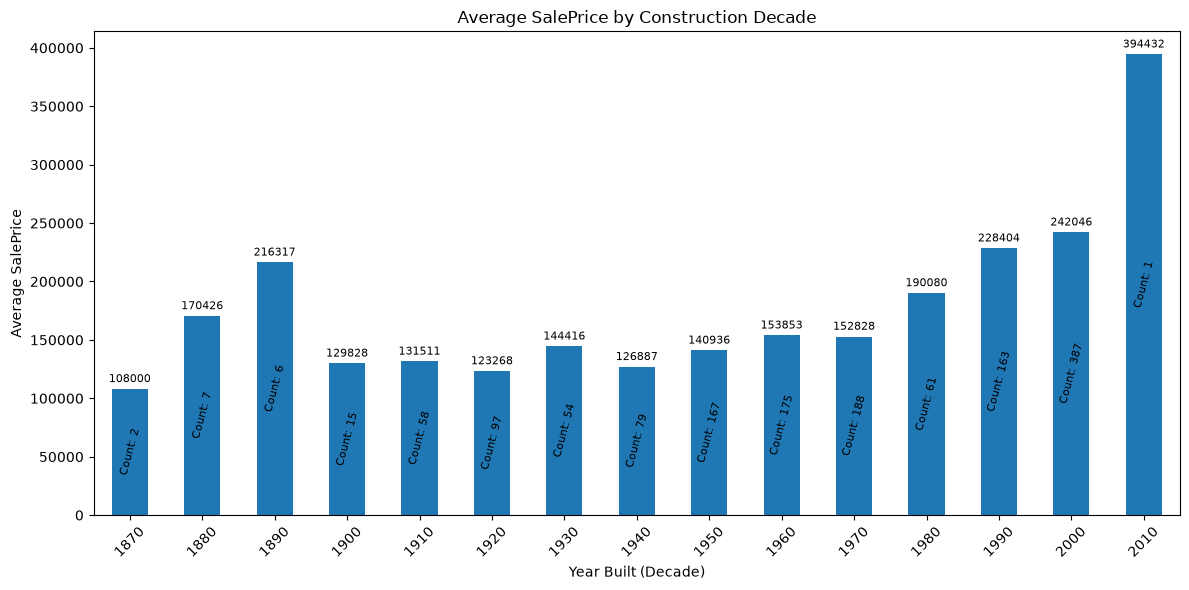

In [150]:
# Average SalePrice by decade
year_price = df.groupby(
    (df["YearBuilt"] // 10) * 10
)["SalePrice"].mean()

# House count by decade
year_count = df.groupby(
    (df["YearBuilt"] // 10) * 10
).size()

# Create figure
plt.figure(figsize=(12, 6))

# Create bar chart
ax = year_price.plot(kind="bar")

# Chart title and labels
plt.title("Average SalePrice by Construction Decade")
plt.xlabel("Year Built (Decade)")
plt.ylabel("Average SalePrice")

# Average price above bars
ax.bar_label(ax.containers[0],fmt='%.0f',label_type='edge',color='black',padding=3,fontsize=8)

# House count inside bars
for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()
    count = year_count.loc[year_price.index[i]]

    ax.text(bar.get_x() + bar.get_width()/2,height/2,f"Count: {count}",ha='center',va='center',rotation=75,color='black',fontsize=8)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# YearRemodAdd  (Iska matlab hai house ka last remodeling (renovation / major improvement) kis year mein hua tha.)

In [151]:
df["YearRemodAdd"].describe()

count    1460.000000
mean     1984.865753
std        20.645407
min      1950.000000
25%      1967.000000
50%      1994.000000
75%      2004.000000
max      2010.000000
Name: YearRemodAdd, dtype: float64

In [153]:
df.groupby((df["YearRemodAdd"] // 10) * 10)["SalePrice"].mean().round(2)

YearRemodAdd
1950    121633.67
1960    146434.39
1970    147556.08
1980    176031.93
1990    206038.64
2000    217312.91
2010    336963.50
Name: SalePrice, dtype: float64

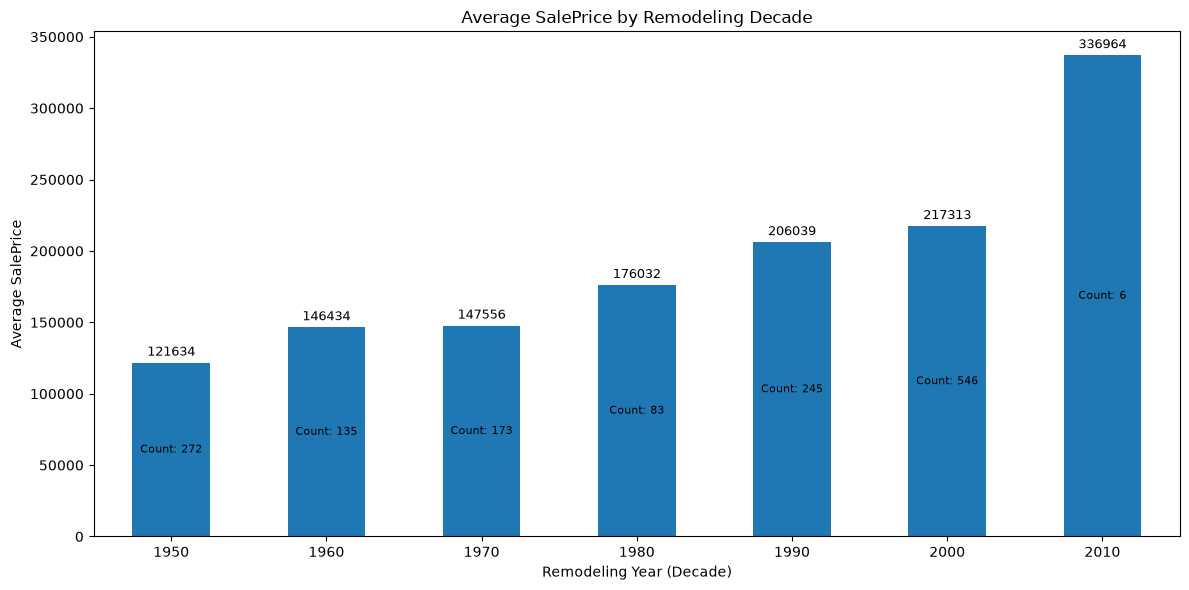

In [155]:
# Average SalePrice by remodeling decade
remod_price = df.groupby(
    (df["YearRemodAdd"] // 10) * 10
)["SalePrice"].mean()

# House count by remodeling decade
remod_count = df.groupby(
    (df["YearRemodAdd"] // 10) * 10
).size()

# Create figure
plt.figure(figsize=(12, 6))

# Create bar chart
ax = remod_price.plot(kind="bar")

# Chart title and labels
plt.title("Average SalePrice by Remodeling Decade")
plt.xlabel("Remodeling Year (Decade)")
plt.ylabel("Average SalePrice")

# Average price above bars
ax.bar_label(ax.containers[0],fmt='%.0f',label_type='edge',color='black',padding=3,fontsize=9)

# House count inside bars
for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()
    count = remod_count.loc[remod_price.index[i]]

    ax.text(bar.get_x() + bar.get_width()/2,height/2,f"Count: {count}",ha='center',va='center',rotation=0,color='black',fontsize=8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [156]:
# GarageArea (GarageArea ka matlab hai garage ka total area, jo square feet (sq ft) mein measure hota hai.)

In [157]:
df["GarageArea"].describe()

count    1460.000000
mean      472.980137
std       213.804841
min         0.000000
25%       334.500000
50%       480.000000
75%       576.000000
max      1418.000000
Name: GarageArea, dtype: float64

In [158]:
df.groupby(pd.cut(df["GarageArea"], bins=5, include_lowest=True),observed=True)["SalePrice"].mean()

GarageArea
(-1.4189999999999998, 283.6]    119797.681452
(283.6, 567.2]                  167053.036570
(567.2, 850.8]                  235438.187861
(850.8, 1134.4]                 282855.522388
(1134.4, 1418.0]                258188.333333
Name: SalePrice, dtype: float64

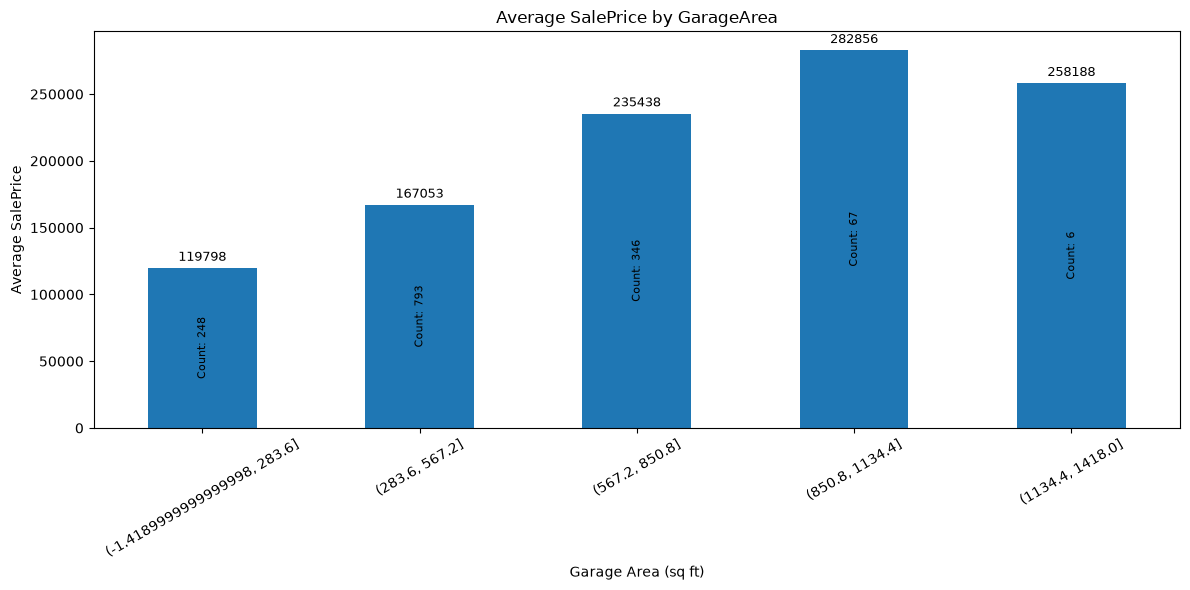

In [159]:
# Divide GarageArea into 5 ranges
garage_bins = pd.cut(df["GarageArea"], bins=5, include_lowest=True)

# Average SalePrice for each range
garage_price = df.groupby(
    garage_bins,
    observed=True
)["SalePrice"].mean()

# House count for each range
garage_count = df.groupby(
    garage_bins,
    observed=True
).size()

# Create figure
plt.figure(figsize=(12, 6))

# Create bar chart
ax = garage_price.plot(kind="bar")

# Chart title and labels
plt.title("Average SalePrice by GarageArea")
plt.xlabel("Garage Area (sq ft)")
plt.ylabel("Average SalePrice")

# Average price above bars
ax.bar_label(
    ax.containers[0],
    fmt='%.0f',
    label_type='edge',
    color='black',
    padding=3,
    fontsize=9
)

# House count inside bars
for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()
    count = garage_count.iloc[i]

    ax.text(
        bar.get_x() + bar.get_width()/2,
        height/2,
        f"Count: {count}",
        ha='center',
        va='center',
        rotation=90,
        color='black',
        fontsize=8
    )

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [160]:
# TotalBsmtSF (TotalBsmtSF ka matlab hai house ke basement ka total area, jo square feet (sq ft) mein measure hota hai.)

In [161]:
df["TotalBsmtSF"].describe()

count    1460.000000
mean     1057.429452
std       438.705324
min         0.000000
25%       795.750000
50%       991.500000
75%      1298.250000
max      6110.000000
Name: TotalBsmtSF, dtype: float64

In [162]:
df.groupby(pd.cut(df["TotalBsmtSF"], bins=5, include_lowest=True),observed=True)["SalePrice"].mean()

TotalBsmtSF
(-6.111000000000001, 1222.0]    153526.177043
(1222.0, 2444.0]                244615.967059
(2444.0, 3666.0]                366375.000000
(4888.0, 6110.0]                160000.000000
Name: SalePrice, dtype: float64

In [163]:
bsmt_bins = pd.cut(df["TotalBsmtSF"], bins=5, include_lowest=True)

df.groupby(bsmt_bins, observed=False).size()

TotalBsmtSF
(-6.111000000000001, 1222.0]    1028
(1222.0, 2444.0]                 425
(2444.0, 3666.0]                   6
(3666.0, 4888.0]                   0
(4888.0, 6110.0]                   1
dtype: int64

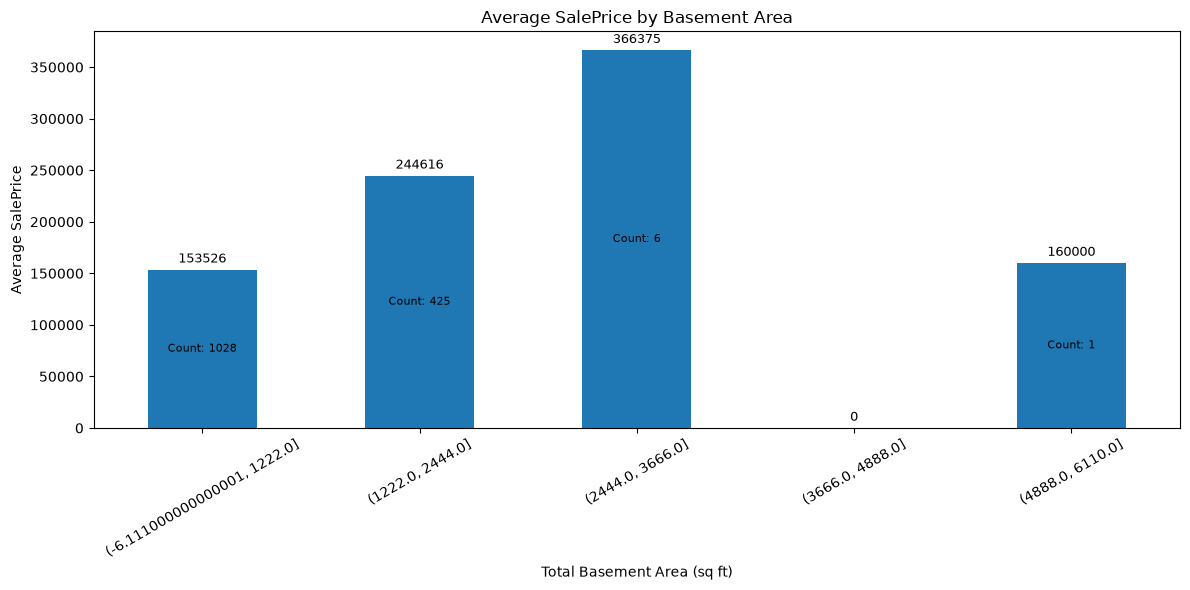

In [165]:
# Create bins
bsmt_bins = pd.cut(
    df["TotalBsmtSF"],
    bins=5,
    include_lowest=True
)

# Average SalePrice
bsmt_price = df.groupby(
    bsmt_bins,
    observed=False
)["SalePrice"].mean()

# House Count
bsmt_count = df.groupby(
    bsmt_bins,
    observed=False
).size()

# Create figure
plt.figure(figsize=(12, 6))

# Create bar chart
ax = bsmt_price.plot(kind="bar")

# Chart title and labels
plt.title("Average SalePrice by Basement Area")
plt.xlabel("Total Basement Area (sq ft)")
plt.ylabel("Average SalePrice")

# Average price above bars
ax.bar_label(
    ax.containers[0],
    fmt='%.0f',
    label_type='edge',
    color='black',
    padding=3,
    fontsize=9
)

# House Count inside bars
for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()

    if pd.notna(height) and bsmt_count.iloc[i] > 0:
        ax.text(
            bar.get_x() + bar.get_width()/2,
            height/2,
            f"Count: {bsmt_count.iloc[i]}",
            ha='center',
            va='center',
            rotation=0,
            color='black',
            fontsize=8
        )

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
#1stFlrSF (1stFlrSF ka matlab hai house ke First Floor ka area, square feet (sq ft) mein.)

In [178]:
df["1stFlrSF"].describe().round(2)

count    1460.00
mean     1162.63
std       386.59
min       334.00
25%       882.00
50%      1087.00
75%      1391.25
max      4692.00
Name: 1stFlrSF, dtype: float64

In [177]:
df.groupby(pd.cut(df["1stFlrSF"], bins=5, include_lowest=True),observed=False)["SalePrice"].mean().round(2)

1stFlrSF
(329.641, 1205.6]    150379.30
(1205.6, 2077.2]     223830.56
(2077.2, 2948.8]     358038.64
(2948.8, 3820.4]     307375.00
(3820.4, 4692.0]     160000.00
Name: SalePrice, dtype: float64

In [168]:
flr_bins = pd.cut(df["1stFlrSF"],bins=5,include_lowest=True)

df.groupby(flr_bins, observed=False).size()

1stFlrSF
(329.641, 1205.6]    900
(1205.6, 2077.2]     532
(2077.2, 2948.8]      25
(2948.8, 3820.4]       2
(3820.4, 4692.0]       1
dtype: int64

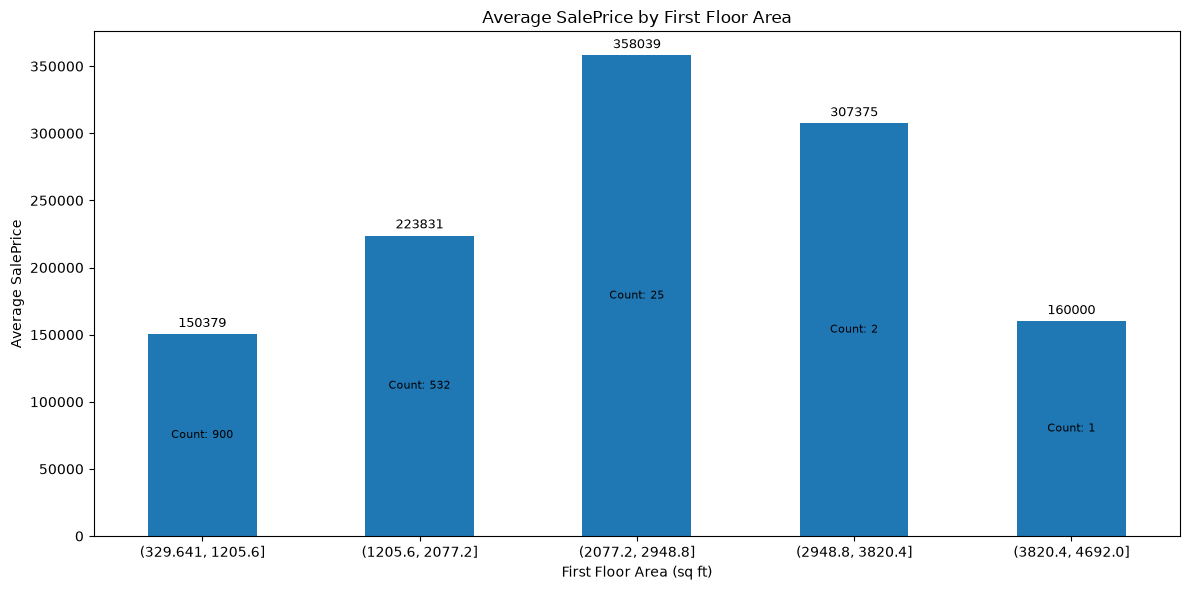

In [171]:
# Divide First Floor Area into 5 ranges
flr_bins = pd.cut(df["1stFlrSF"],bins=5,include_lowest=True)

# Average SalePrice
flr_price = df.groupby(flr_bins,observed=False)["SalePrice"].mean()

# House Count
flr_count = df.groupby(flr_bins,observed=False).size()

# Create figure
plt.figure(figsize=(12, 6))

# Create bar chart
ax = flr_price.plot(kind="bar")

# Chart title and labels
plt.title("Average SalePrice by First Floor Area")
plt.xlabel("First Floor Area (sq ft)")
plt.ylabel("Average SalePrice")

# Average price above bars
ax.bar_label(ax.containers[0],fmt='%.0f',label_type='edge',color='black',padding=3,fontsize=9)

# House Count inside bars
for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()
    count = flr_count.iloc[i]

    ax.text(bar.get_x() + bar.get_width()/2,height/2,f"Count: {count}",ha='center',va='center',rotation=0,color='black',fontsize=8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [179]:
# GrLivArea (Above Ground Living Area.)

df["GrLivArea"].describe().round(2)

count    1460.00
mean     1515.46
std       525.48
min       334.00
25%      1129.50
50%      1464.00
75%      1776.75
max      5642.00
Name: GrLivArea, dtype: float64

In [180]:
df.groupby(pd.cut(df["GrLivArea"], bins=5, include_lowest=True),observed=False)["SalePrice"].mean().round(2)

GrLivArea
(328.69100000000003, 1395.6]    132458.40
(1395.6, 2457.2]                209856.80
(2457.2, 3518.8]                314621.33
(3518.8, 4580.4]                650000.00
(4580.4, 5642.0]                172375.00
Name: SalePrice, dtype: float64

In [174]:
grliv_bins = pd.cut(df["GrLivArea"],bins=5,include_lowest=True)

df.groupby(grliv_bins, observed=False).size()

GrLivArea
(328.69100000000003, 1395.6]    661
(1395.6, 2457.2]                724
(2457.2, 3518.8]                 69
(3518.8, 4580.4]                  4
(4580.4, 5642.0]                  2
dtype: int64

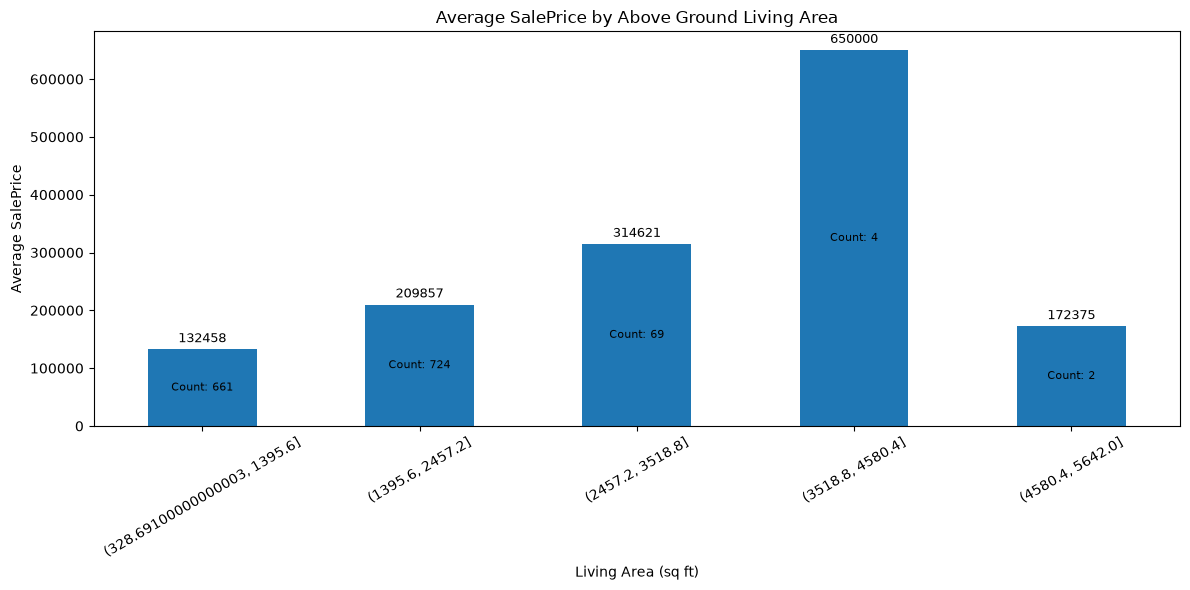

In [176]:
# Divide GrLivArea into 5 ranges
grliv_bins = pd.cut(df["GrLivArea"],bins=5,include_lowest=True)

# Average SalePrice
grliv_price = df.groupby(grliv_bins,observed=False)["SalePrice"].mean()

# House Count
grliv_count = df.groupby(grliv_bins,observed=False).size()

# Create figure
plt.figure(figsize=(12, 6))

# Create bar chart
ax = grliv_price.plot(kind="bar")

# Chart title and labels
plt.title("Average SalePrice by Above Ground Living Area")
plt.xlabel("Living Area (sq ft)")
plt.ylabel("Average SalePrice")

# Average price above bars
ax.bar_label(ax.containers[0],fmt='%.0f',label_type='edge',color='black',padding=3,fontsize=9)

# House Count inside bars
for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()
    count = grliv_count.iloc[i]

    ax.text(bar.get_x() + bar.get_width()/2,height/2,f"Count: {count}",ha='center',va='center',rotation=0,color='black',fontsize=8)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
 # LotArea  (LotArea ka matlab hai house jis total land/plot par bana hai, uska area square feet (sq ft) mein.)

In [181]:
df["LotArea"].describe()

count      1460.000000
mean      10516.828082
std        9981.264932
min        1300.000000
25%        7553.500000
50%        9478.500000
75%       11601.500000
max      215245.000000
Name: LotArea, dtype: float64

In [182]:
df.groupby(pd.cut(df["LotArea"], bins=5, include_lowest=True),observed=False)["SalePrice"].mean()

LotArea
(1086.054, 44089.0]     179890.114720
(44089.0, 86878.0]      295666.666667
(86878.0, 129667.0]     302000.000000
(129667.0, 172456.0]    252975.000000
(172456.0, 215245.0]    375000.000000
Name: SalePrice, dtype: float64

In [183]:
lot_bins = pd.cut(df["LotArea"], bins=5, include_lowest=True)

df.groupby(lot_bins, observed=False).size()

LotArea
(1086.054, 44089.0]     1447
(44089.0, 86878.0]         9
(86878.0, 129667.0]        1
(129667.0, 172456.0]       2
(172456.0, 215245.0]       1
dtype: int64

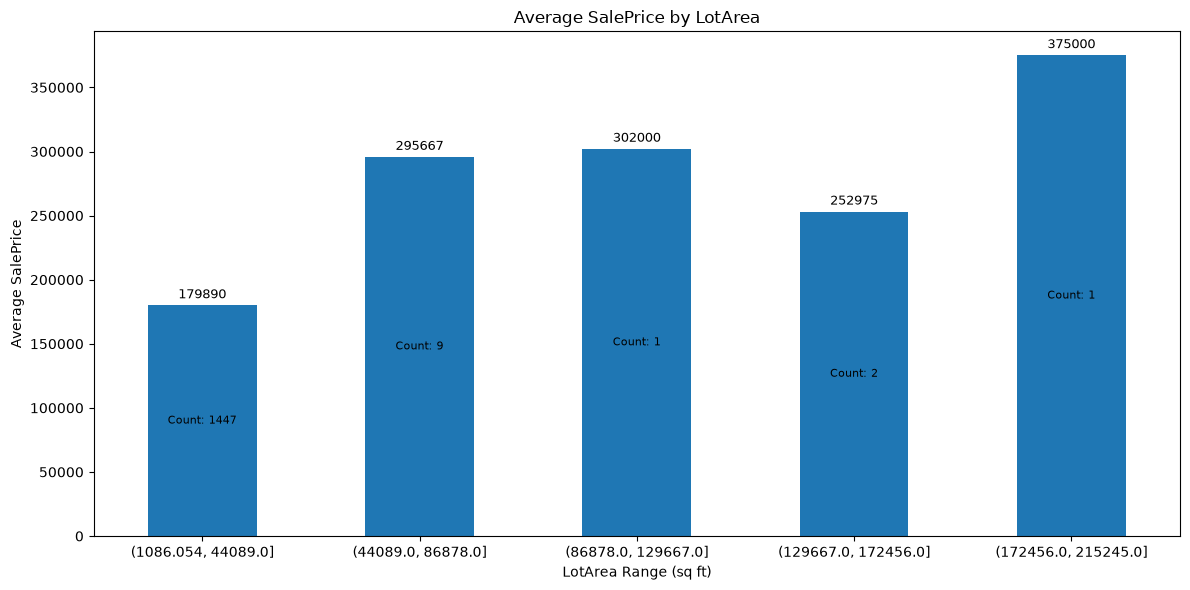

In [186]:
lot_bins = pd.cut(df["LotArea"], bins=5, include_lowest=True)

lot_price = df.groupby(lot_bins, observed=False)["SalePrice"].mean()
lot_count = df.groupby(lot_bins, observed=False).size()

plt.figure(figsize=(12, 6))

ax = lot_price.plot(kind="bar")

plt.title("Average SalePrice by LotArea")
plt.xlabel("LotArea Range (sq ft)")
plt.ylabel("Average SalePrice")

ax.bar_label(ax.containers[0],fmt='%.0f',label_type='edge',color='black',padding=3,fontsize=9)

for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()
    count = lot_count.iloc[i]

    ax.text(bar.get_x() + bar.get_width()/2,height/2,f"Count: {count}",ha='center',va='center',rotation=0,color='black',fontsize=8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# OverallCond (OverallCond house ki overall condition ko represent karta hai — yani house ki current condition aur maintenance kaisi hai.)

In [187]:
df["OverallCond"].value_counts().sort_index()

OverallCond
1      1
2      5
3     25
4     57
5    821
6    252
7    205
8     72
9     22
Name: count, dtype: int64

In [189]:
df.groupby("OverallCond")["SalePrice"].mean().round()

OverallCond
1     61000.0
2    141986.0
3    101929.0
4    120438.0
5    203147.0
6    153962.0
7    158145.0
8    155652.0
9    216005.0
Name: SalePrice, dtype: float64

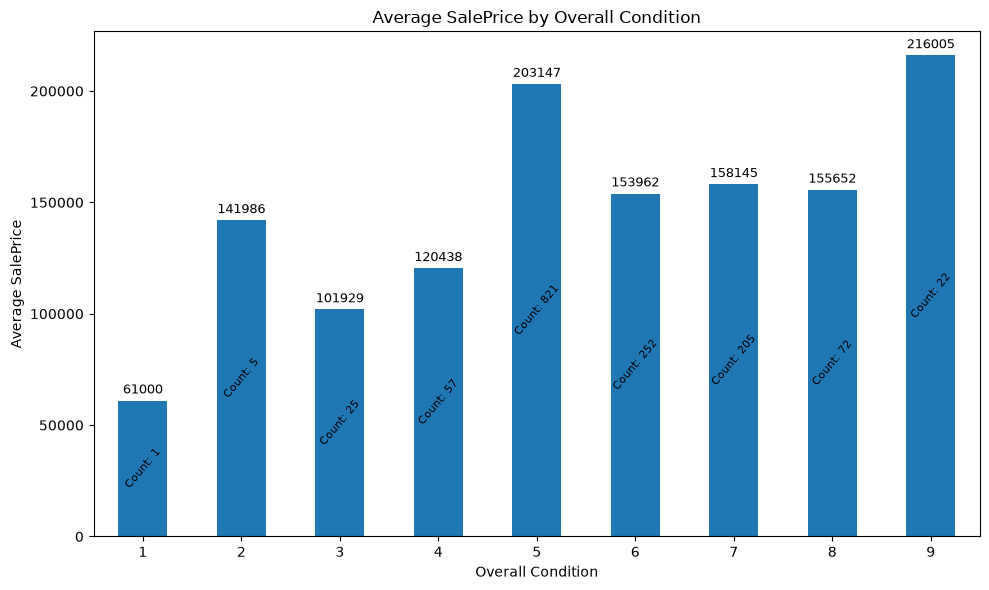

In [191]:
condition_price = df.groupby("OverallCond")["SalePrice"].mean()
condition_count = df["OverallCond"].value_counts().sort_index()

plt.figure(figsize=(10, 6))

ax = condition_price.plot(kind="bar")

plt.title("Average SalePrice by Overall Condition")
plt.xlabel("Overall Condition")
plt.ylabel("Average SalePrice")

ax.bar_label(ax.containers[0],fmt="%.0f",label_type="edge",color="black",padding=3,fontsize=9)

for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()
    count = condition_count.loc[condition_price.index[i]]

    ax.text(bar.get_x() + bar.get_width()/2,height/2,f"Count: {count}",ha="center",va="center",rotation=50,color="black",fontsize=8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# TotRmsAbvGrd  (Total Rooms Above Ground)

In [192]:
df["TotRmsAbvGrd"].value_counts().sort_index()

TotRmsAbvGrd
2       1
3      17
4      97
5     275
6     402
7     329
8     187
9      75
10     47
11     18
12     11
14      1
Name: count, dtype: int64

In [194]:
df.groupby("TotRmsAbvGrd")["SalePrice"].mean().round()

TotRmsAbvGrd
2      39300.0
3     111218.0
4     122845.0
5     141551.0
6     161303.0
7     196667.0
8     213428.0
9     252988.0
10    296279.0
11    318022.0
12    280971.0
14    200000.0
Name: SalePrice, dtype: float64

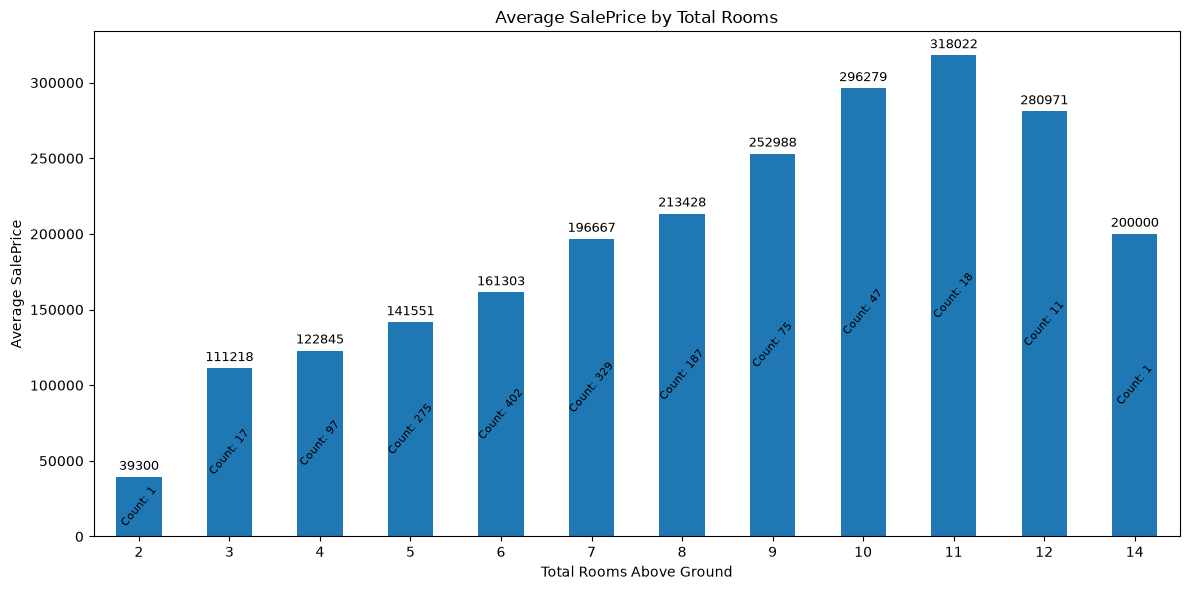

In [196]:
rooms_price = df.groupby("TotRmsAbvGrd")["SalePrice"].mean()
rooms_count = df["TotRmsAbvGrd"].value_counts().sort_index()

plt.figure(figsize=(12, 6))

ax = rooms_price.plot(kind="bar")

plt.title("Average SalePrice by Total Rooms")
plt.xlabel("Total Rooms Above Ground")
plt.ylabel("Average SalePrice")

ax.bar_label(ax.containers[0],fmt="%.0f",label_type="edge",color="black",padding=3,fontsize=9)

for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()
    count = rooms_count.loc[rooms_price.index[i]]

    ax.text(bar.get_x() + bar.get_width()/2,height/2,f"Count: {count}",ha="center",va="center",rotation=50,color="black",fontsize=8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# KitchenQual (KitchenQual house ki Kitchen Quality ko represent karta hai.)

In [197]:
df["KitchenQual"].value_counts()

KitchenQual
TA    735
Gd    586
Ex    100
Fa     39
Name: count, dtype: int64

In [199]:
df.groupby("KitchenQual")["SalePrice"].mean().round()

KitchenQual
Ex    328555.0
Fa    105565.0
Gd    212116.0
TA    139963.0
Name: SalePrice, dtype: float64

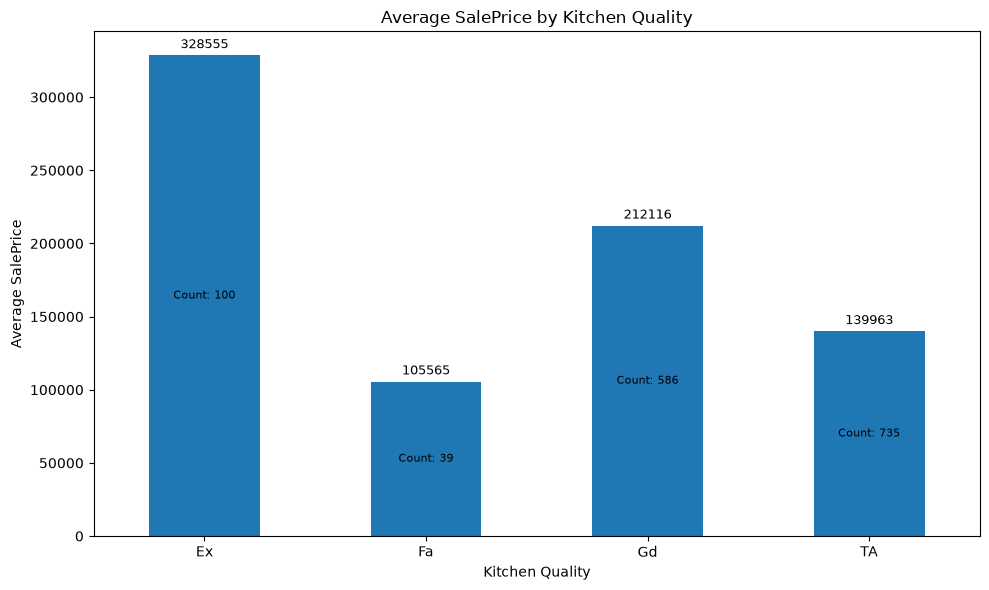

In [201]:
kitchen_price = df.groupby("KitchenQual")["SalePrice"].mean()

kitchen_count = df["KitchenQual"].value_counts().reindex(
    kitchen_price.index
)

plt.figure(figsize=(10, 6))

ax = kitchen_price.plot(kind="bar")

plt.title("Average SalePrice by Kitchen Quality")
plt.xlabel("Kitchen Quality")
plt.ylabel("Average SalePrice")

ax.bar_label(ax.containers[0],fmt="%.0f",label_type="edge",color="black",padding=3,fontsize=9)

for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()
    count = kitchen_count.iloc[i]

    ax.text(bar.get_x() + bar.get_width()/2,height/2,f"Count: {count}",ha="center",va="center",rotation=0,color="black",fontsize=8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# ExterQual (Exterior Quality.)

In [202]:
df["ExterQual"].value_counts()

ExterQual
TA    906
Gd    488
Ex     52
Fa     14
Name: count, dtype: int64

In [203]:
df.groupby("ExterQual")["SalePrice"].mean().round()

ExterQual
Ex    367361.0
Fa     87985.0
Gd    231634.0
TA    144341.0
Name: SalePrice, dtype: float64

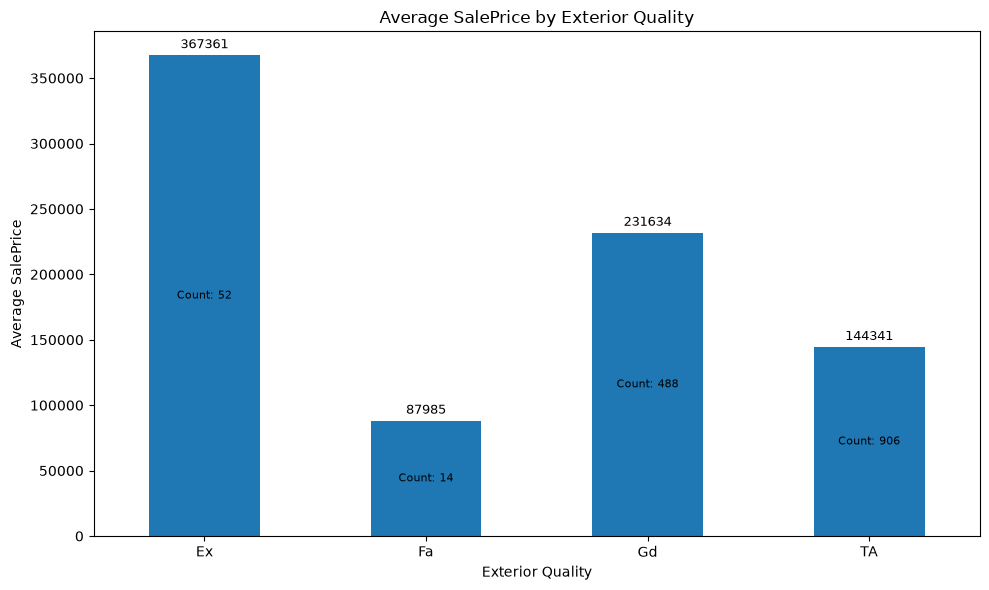

In [205]:
exterior_price = df.groupby("ExterQual")["SalePrice"].mean()

exterior_count = df["ExterQual"].value_counts().reindex(
    exterior_price.index
)

plt.figure(figsize=(10, 6))

ax = exterior_price.plot(kind="bar")

plt.title("Average SalePrice by Exterior Quality")
plt.xlabel("Exterior Quality")
plt.ylabel("Average SalePrice")

ax.bar_label(
    ax.containers[0],
    fmt="%.0f",
    label_type="edge",
    color="black",
    padding=3,
    fontsize=9
)

for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()
    count = exterior_count.iloc[i]

    ax.text(
        bar.get_x() + bar.get_width()/2,
        height/2,
        f"Count: {count}",
        ha="center",
        va="center",
        rotation=0,
        color="black",
        fontsize=8
    )

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# SaleCondition (SaleCondition batata hai ki house kis type ki sale condition ke under sell hua tha.)

In [206]:
df["SaleCondition"].value_counts()

SaleCondition
Normal     1198
Partial     125
Abnorml     101
Family       20
Alloca       12
AdjLand       4
Name: count, dtype: int64

In [207]:
df.groupby("SaleCondition")["SalePrice"].mean()

SaleCondition
Abnorml    146526.623762
AdjLand    104125.000000
Alloca     167377.416667
Family     149600.000000
Normal     175202.219533
Partial    272291.752000
Name: SalePrice, dtype: float64

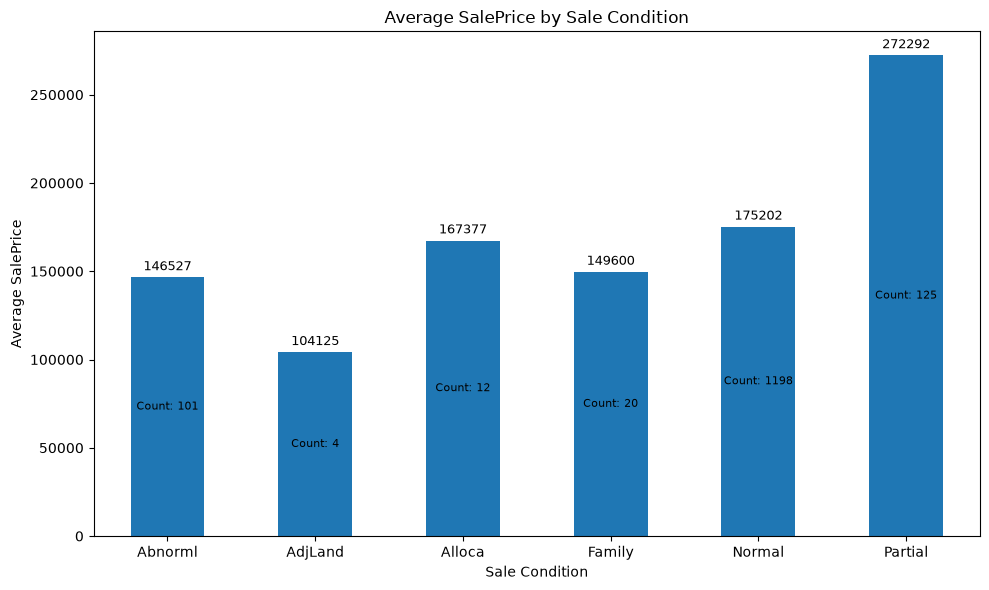

In [209]:
sale_price = df.groupby("SaleCondition")["SalePrice"].mean()
sale_count = df["SaleCondition"].value_counts().reindex(
    sale_price.index
)

plt.figure(figsize=(10, 6))

ax = sale_price.plot(kind="bar")

plt.title("Average SalePrice by Sale Condition")
plt.xlabel("Sale Condition")
plt.ylabel("Average SalePrice")

ax.bar_label(ax.containers[0],fmt="%.0f",label_type="edge",color="black",padding=3,fontsize=9)

for i, bar in enumerate(ax.containers[0]):
    height = bar.get_height()
    count = sale_count.iloc[i]

    ax.text(bar.get_x() + bar.get_width()/2,height/2,f"Count: {count}",ha="center",va="center",rotation=0,color="black",fontsize=8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# EDA Summary & Data Cleaning

# missing values

In [212]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

display(missing)


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [226]:
missing_percentage = round((df.isnull().sum() / len(df)) * 100,2)

missing_percentage = missing_percentage[missing_percentage > 0].sort_values(ascending=False)

display(missing_percentage)

PoolQC          99.52
MiscFeature     96.30
Alley           93.77
Fence           80.75
MasVnrType      59.73
FireplaceQu     47.26
LotFrontage     17.74
GarageType       5.55
GarageYrBlt      5.55
GarageFinish     5.55
GarageQual       5.55
GarageCond       5.55
BsmtExposure     2.60
BsmtFinType2     2.60
BsmtQual         2.53
BsmtCond         2.53
BsmtFinType1     2.53
MasVnrArea       0.55
Electrical       0.07
dtype: float64

In [218]:
df[["PoolQC", "PoolArea"]].head(20)

,PoolQC,PoolArea
0,NaN,0
1,NaN,0
2,NaN,0
3,NaN,0
4,NaN,0
5,NaN,0
6,NaN,0
7,NaN,0
8,NaN,0
9,NaN,0


In [219]:
df["PoolArea"].value_counts()

PoolArea
0      1453
512       1
648       1
576       1
555       1
480       1
519       1
738       1
Name: count, dtype: int64

In [ ]:
# MiscFeature (missing values)

In [220]:
df["MiscFeature"].value_counts(dropna=False)

MiscFeature
NaN     1406
Shed      49
Gar2       2
Othr       2
TenC       1
Name: count, dtype: int64

In [221]:
df["Alley"].value_counts(dropna=False)

Alley
NaN     1369
Grvl      50
Pave      41
Name: count, dtype: int64

In [ ]:
# Fence

In [222]:
df["Fence"].value_counts(dropna=False)

Fence
NaN      1179
MnPrv     157
GdPrv      59
GdWo       54
MnWw       11
Name: count, dtype: int64

In [ ]:
# MasVnrType

In [227]:
df["MasVnrType"].value_counts(dropna=False)

MasVnrType
NaN        872
BrkFace    445
Stone      128
BrkCmn      15
Name: count, dtype: int64

In [228]:
df[["MasVnrType", "MasVnrArea"]].head(20)

,MasVnrType,MasVnrArea
0,BrkFace,196.0
1,NaN,0.0
2,BrkFace,162.0
3,NaN,0.0
4,BrkFace,350.0
5,NaN,0.0
6,Stone,186.0
7,Stone,240.0
8,NaN,0.0
9,NaN,0.0


In [229]:
df.groupby("MasVnrType", dropna=False)["MasVnrArea"].agg(["count", "min", "max", "mean"])

,count,min,max,mean
MasVnrType,,,,
BrkCmn,15,41.0,621.0,247.666667
BrkFace,445,0.0,1600.0,259.008989
Stone,128,0.0,860.0,239.304688
NaN,864,0.0,344.0,1.094907


In [230]:
df[(df["MasVnrType"].isnull()) &(df["MasVnrArea"] > 0)][["MasVnrType", "MasVnrArea"]]

,MasVnrType,MasVnrArea
624,NaN,288.0
773,NaN,1.0
1230,NaN,1.0
1300,NaN,344.0
1334,NaN,312.0


In [231]:
df[df["MasVnrArea"].isnull()][["MasVnrType", "MasVnrArea"]]

,MasVnrType,MasVnrArea
234,NaN,NaN
529,NaN,NaN
650,NaN,NaN
936,NaN,NaN
973,NaN,NaN
977,NaN,NaN
1243,NaN,NaN
1278,NaN,NaN


In [232]:
# FireplaceQu

In [233]:
df["FireplaceQu"].value_counts(dropna=False)

FireplaceQu
NaN    690
Gd     380
TA     313
Fa      33
Ex      24
Po      20
Name: count, dtype: int64

In [234]:
df["Fireplaces"].value_counts(dropna=False)

Fireplaces
0    690
1    650
2    115
3      5
Name: count, dtype: int64

In [ ]:
# LotFrontage  (property ke plot ki woh length jo street/road ko touch karti hai.)

In [238]:
df["LotFrontage"].value_counts(dropna=False)

LotFrontage
NaN      259
60.0     143
70.0      70
80.0      69
50.0      57
        ... 
138.0      1
160.0      1
152.0      1
153.0      1
46.0       1
Name: count, Length: 111, dtype: int64

In [237]:
df["LotFrontage"].describe() 

count    1201.000000
mean       70.049958
std        24.284752
min        21.000000
25%        59.000000
50%        69.000000
75%        80.000000
max       313.000000
Name: LotFrontage, dtype: float64

In [239]:
df.groupby("Neighborhood")["LotFrontage"].median()

Neighborhood
Blmngtn    43.0
Blueste    24.0
BrDale     21.0
BrkSide    52.0
ClearCr    80.0
CollgCr    70.0
Crawfor    74.0
Edwards    65.5
Gilbert    65.0
IDOTRR     60.0
MeadowV    21.0
Mitchel    73.0
NAmes      73.0
NPkVill    24.0
NWAmes     80.0
NoRidge    91.0
NridgHt    88.5
OldTown    60.0
SWISU      60.0
Sawyer     71.0
SawyerW    66.5
Somerst    73.5
StoneBr    61.5
Timber     85.0
Veenker    68.0
Name: LotFrontage, dtype: float64

In [ ]:
# Garage columns

In [240]:
df[["GarageType","GarageYrBlt","GarageFinish","GarageCars","GarageArea","GarageQual","GarageCond"]].isnull().sum()

GarageType      81
GarageYrBlt     81
GarageFinish    81
GarageCars       0
GarageArea       0
GarageQual      81
GarageCond      81
dtype: int64

In [241]:
df[df["GarageType"].isnull()][["GarageType","GarageYrBlt","GarageFinish","GarageCars","GarageArea","GarageQual","GarageCond"]]

,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond
39,NaN,NaN,NaN,0,0,NaN,NaN
48,NaN,NaN,NaN,0,0,NaN,NaN
78,NaN,NaN,NaN,0,0,NaN,NaN
88,NaN,NaN,NaN,0,0,NaN,NaN
89,NaN,NaN,NaN,0,0,NaN,NaN
...,...,...,...,...,...,...,...
1349,NaN,NaN,NaN,0,0,NaN,NaN
1407,NaN,NaN,NaN,0,0,NaN,NaN
1449,NaN,NaN,NaN,0,0,NaN,NaN
1450,NaN,NaN,NaN,0,0,NaN,NaN


In [244]:
# Basement columns 

In [243]:
 df[["BsmtQual","BsmtCond","BsmtExposure","BsmtFinType1","BsmtFinType2","TotalBsmtSF"]].isnull().sum()

BsmtQual        37
BsmtCond        37
BsmtExposure    38
BsmtFinType1    37
BsmtFinType2    38
TotalBsmtSF      0
dtype: int64

In [245]:
df[df["BsmtQual"].isnull()][["BsmtQual","BsmtCond","BsmtExposure","BsmtFinType1","BsmtFinType2","TotalBsmtSF"]]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,TotalBsmtSF
17,NaN,NaN,NaN,NaN,NaN,0
39,NaN,NaN,NaN,NaN,NaN,0
90,NaN,NaN,NaN,NaN,NaN,0
102,NaN,NaN,NaN,NaN,NaN,0
156,NaN,NaN,NaN,NaN,NaN,0
182,NaN,NaN,NaN,NaN,NaN,0
259,NaN,NaN,NaN,NaN,NaN,0
342,NaN,NaN,NaN,NaN,NaN,0
362,NaN,NaN,NaN,NaN,NaN,0
371,NaN,NaN,NaN,NaN,NaN,0


In [246]:
df[df["BsmtExposure"].isnull() &df["BsmtQual"].notnull()][["BsmtQual","BsmtCond","BsmtExposure","BsmtFinType1","BsmtFinType2","TotalBsmtSF"]]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,TotalBsmtSF
948,Gd,TA,NaN,Unf,Unf,936


In [247]:
df[df["BsmtFinType2"].isnull() &df["BsmtQual"].notnull()][["BsmtQual","BsmtCond","BsmtExposure","BsmtFinType1","BsmtFinType2","TotalBsmtSF"]]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,TotalBsmtSF
332,Gd,TA,No,GLQ,NaN,3206


In [ ]:
# Electrical

In [248]:
df["Electrical"].value_counts(dropna=False)

Electrical
SBrkr    1334
FuseA      94
FuseF      27
FuseP       3
Mix         1
NaN         1
Name: count, dtype: int64

In [249]:
df[df["Electrical"].isnull()]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1379,1380,80,RL,73.0,9735,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,167500


In [250]:
df["Electrical"].mode()

0    SBrkr
Name: Electrical, dtype: str

In [ ]:
# MasVnrArea (Masonry Veneer)

In [251]:
df[df["MasVnrArea"].isnull()][["MasVnrType", "MasVnrArea"]]

,MasVnrType,MasVnrArea
234,NaN,NaN
529,NaN,NaN
650,NaN,NaN
936,NaN,NaN
973,NaN,NaN
977,NaN,NaN
1243,NaN,NaN
1278,NaN,NaN


In [252]:
df["MasVnrArea"].median()

np.float64(0.0)

In [253]:
df["MasVnrArea"].value_counts().sort_index()

MasVnrArea
0.0       861
1.0         2
11.0        1
14.0        1
16.0        7
         ... 
1115.0      1
1129.0      1
1170.0      1
1378.0      1
1600.0      1
Name: count, Length: 327, dtype: int64

In [254]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

display(missing)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [ ]:
# cleaning part

In [ ]:
df_clean = df.copy()

In [256]:
# 4 columns (PoolQC,MiscFeature,Alley,Fence)

df_clean["PoolQC"] = df_clean["PoolQC"].fillna("NoPool")

df_clean["MiscFeature"] = df_clean["MiscFeature"].fillna("NoFeature")

df_clean["Alley"] = df_clean["Alley"].fillna("NoAlley")

df_clean["Fence"] = df_clean["Fence"].fillna("NoFence")

In [257]:
df_clean[["PoolQC", "MiscFeature", "Alley", "Fence"]].isnull().sum()

PoolQC         0
MiscFeature    0
Alley          0
Fence          0
dtype: int64

In [258]:
# 2 columns (MasVnrType,MasVnrArea)

# Part A: MasVnrArea

df_clean["MasVnrArea"] = df_clean["MasVnrArea"].fillna(0)

In [259]:
#Part B: MasVnrType

df_clean.loc[df_clean["MasVnrType"].isnull() & (df_clean["MasVnrArea"] == 0),"MasVnrType"] = "None"

df_clean.loc[df_clean["MasVnrType"].isnull(),"MasVnrType"] = "Unknown"

In [260]:
df_clean[["MasVnrType", "MasVnrArea"]].isnull().sum()

MasVnrType    0
MasVnrArea    0
dtype: int64

In [261]:
# 1 column (FireplaceQu)

df_clean["FireplaceQu"] = df_clean["FireplaceQu"].fillna("NoFireplace")

In [262]:
df_clean["FireplaceQu"].isnull().sum()

np.int64(0)

In [263]:
# 1 column (LotFrontage – Neighborhood-wise Median)

df_clean["LotFrontage"] = df_clean.groupby("Neighborhood")["LotFrontage"].transform(lambda x: x.fillna(x.median()))

In [264]:
df_clean["LotFrontage"].isnull().sum()

np.int64(0)

In [266]:
# 7 columns (Garage columns – Verification)

df_clean["GarageType"] = df_clean["GarageType"].fillna("NoGarage")

df_clean["GarageFinish"] = df_clean["GarageFinish"].fillna("NoGarage")

df_clean["GarageQual"] = df_clean["GarageQual"].fillna("NoGarage")

df_clean["GarageCond"] = df_clean["GarageCond"].fillna("NoGarage")

df_clean["GarageYrBlt"] = df_clean["GarageYrBlt"].fillna(0)

In [267]:
df_clean[["GarageType","GarageYrBlt","GarageFinish","GarageQual","GarageCond"]].isnull().sum()

GarageType      0
GarageYrBlt     0
GarageFinish    0
GarageQual      0
GarageCond      0
dtype: int64

In [268]:
# 6 columns (Basement columns cleaning)

basement_cols = ["BsmtQual","BsmtCond","BsmtExposure","BsmtFinType1","BsmtFinType2"]

no_basement = df_clean["TotalBsmtSF"] == 0

for col in basement_cols:
    df_clean.loc[no_basement, col] = (df_clean.loc[no_basement, col].fillna("NoBasement"))

df_clean.loc[948, "BsmtExposure"] = "Unknown"
df_clean.loc[332, "BsmtFinType2"] = "Unknown"

In [269]:
df_clean[basement_cols].isnull().sum()

BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
dtype: int64

In [270]:
# 1 column (Electrical column)

df_clean["Electrical"] = df_clean["Electrical"].fillna(df_clean["Electrical"].mode()[0])


In [271]:
df_clean["Electrical"].isnull().sum()

np.int64(0)

In [272]:
df_clean[["MasVnrType", "MasVnrArea"]].isnull().sum()

MasVnrType    0
MasVnrArea    0
dtype: int64

In [ ]:
# : Complete Missing Values Verification

In [273]:
missing_clean = df_clean.isnull().sum()

missing_clean = missing_clean[missing_clean > 0].sort_values(ascending=False)

display(missing_clean)

Series([], dtype: int64)

In [274]:
print("Total Missing Values:", df_clean.isnull().sum().sum())

Total Missing Values: 0


In [275]:
# Original vs Cleaned Dataset Comparison

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("Original Missing Values:", df.isnull().sum().sum())
print("Cleaned Missing Values:", df_clean.isnull().sum().sum())

Original Dataset Shape: (1460, 81)
Cleaned Dataset Shape: (1460, 81)
Original Missing Values: 7829
Cleaned Missing Values: 0


In [276]:
#duplicate check

df_clean.duplicated().sum()

np.int64(0)

In [277]:
# datatype check

df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          1460 non-null   str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [280]:
# MSSubClass

df_clean["MSSubClass"].value_counts().sort_index()

MSSubClass
20     536
30      69
40       4
45      12
50     144
60     299
70      60
75      16
80      58
85      20
90      52
120     87
160     63
180     10
190     30
Name: count, dtype: int64

In [ ]:
#  convert MSSubClass into category

In [281]:
df_clean["MSSubClass"] = df_clean["MSSubClass"].astype("str")

In [282]:
df_clean["MSSubClass"].dtype

<StringDtype(storage='python', na_value=nan)>

In [ ]:
# Numerical Outliers.

In [283]:
# GrLivArea

df_clean["GrLivArea"].describe()

count    1460.000000
mean     1515.463699
std       525.480383
min       334.000000
25%      1129.500000
50%      1464.000000
75%      1776.750000
max      5642.000000
Name: GrLivArea, dtype: float64

In [284]:
Q1 = df_clean["GrLivArea"].quantile(0.25)
Q3 = df_clean["GrLivArea"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 1129.5
Q3: 1776.75
IQR: 647.25
Lower Limit: 158.625
Upper Limit: 2747.625


In [285]:
outliers = df_clean[(df_clean["GrLivArea"] < lower_limit) |(df_clean["GrLivArea"] > upper_limit)]

print("Total Outliers:", len(outliers))

display(outliers[["Id", "GrLivArea", "SalePrice"]])

Total Outliers: 31


,Id,GrLivArea,SalePrice
58,59,2945,438780
118,119,3222,320000
185,186,3608,475000
197,198,3112,235000
231,232,2794,403000
304,305,3493,295000
324,325,2978,242000
496,497,3228,430000
523,524,4676,184750
583,584,2775,325000


In [286]:
df_clean.loc[[523, 1298],["Id","GrLivArea","SalePrice","OverallQual","OverallCond","YearBuilt","Neighborhood","HouseStyle"]]

,Id,GrLivArea,SalePrice,OverallQual,OverallCond,YearBuilt,Neighborhood,HouseStyle
523,524,4676,184750,10,5,2007,Edwards,2Story
1298,1299,5642,160000,10,5,2008,Edwards,2Story


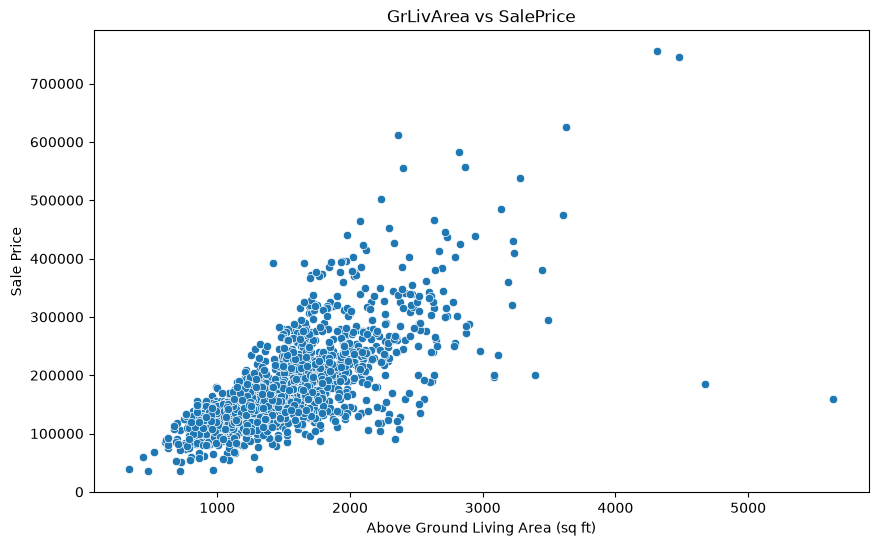

In [287]:
# Scatter Plot

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df_clean,x="GrLivArea",y="SalePrice")

plt.title("GrLivArea vs SalePrice")
plt.xlabel("Above Ground Living Area (sq ft)")
plt.ylabel("Sale Price")

plt.show()

In [288]:
# remove 2 outlier and create new data frame = df_model


df_model = df_clean.drop(index=[523, 1298]).copy()

In [289]:
print("Before:", df_clean.shape)
print("After:", df_model.shape)

Before: (1460, 81)
After: (1458, 81)


In [290]:
# saleprice Outlier

df_model["SalePrice"].describe()

count      1458.000000
mean     180932.919067
std       79495.055285
min       34900.000000
25%      129925.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [291]:
Q1 = df_model["SalePrice"].quantile(0.25)
Q3 = df_model["SalePrice"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 129925.0
Q3: 214000.0
IQR: 84075.0
Lower Limit: 3812.5
Upper Limit: 340112.5


In [292]:
saleprice_outliers = df_model[df_model["SalePrice"] > upper_limit]

print("Total SalePrice Outliers:", len(saleprice_outliers))

display(saleprice_outliers[["Id","SalePrice","OverallQual","GrLivArea","YearBuilt","Neighborhood"]].sort_values(
    "SalePrice", ascending=False))

Total SalePrice Outliers: 61


,Id,SalePrice,OverallQual,GrLivArea,YearBuilt,Neighborhood
691,692,755000,10,4316,1994,NoRidge
1182,1183,745000,10,4476,1996,NoRidge
1169,1170,625000,10,3627,1995,NoRidge
898,899,611657,9,2364,2009,NridgHt
803,804,582933,9,2822,2008,NridgHt
...,...,...,...,...,...,...
990,991,348000,8,2392,1997,NoRidge
642,643,345000,8,2704,1972,NAmes
11,12,345000,9,2324,2005,NridgHt
320,321,342643,9,2596,2006,NridgHt


In [293]:
print("Overall Quality Distribution:")
display(saleprice_outliers["OverallQual"].value_counts().sort_index())

print("Neighborhood Distribution:")
display(saleprice_outliers["Neighborhood"].value_counts())

print("Outliers Area and Price Summary:")
display(
    saleprice_outliers[["GrLivArea", "SalePrice"]].describe()
)

Overall Quality Distribution:


OverallQual
7      3
8     22
9     23
10    13
Name: count, dtype: int64

Neighborhood Distribution:


Neighborhood
NridgHt    27
NoRidge    11
StoneBr     9
Timber      3
Crawfor     3
CollgCr     2
Somerst     2
Veenker     1
OldTown     1
NAmes       1
Gilbert     1
Name: count, dtype: int64

Outliers Area and Price Summary:


,GrLivArea,SalePrice
count,61.000000,61.000000
mean,2456.918033,425954.180328
std,627.271400,89557.255611
min,1419.000000,341000.000000
25%,2018.000000,372500.000000
50%,2364.000000,394617.000000
75%,2728.000000,440000.000000
max,4476.000000,755000.000000


In [294]:
# Id column investigate

df_model["Id"].nunique()

1458

In [295]:
df_model = df_model.drop(columns=["Id"])

In [296]:
df_model.shape

(1458, 80)

In [298]:
# final verification

In [299]:
print("Missing Values:", df_model.isnull().sum().sum())
print("Duplicate Rows:", df_model.duplicated().sum())
print("Data Shape:", df_model.shape)

Missing Values: 0
Duplicate Rows: 0
Data Shape: (1458, 80)


In [300]:
# Constant Columns Check

Street             2
Utilities          2
CentralAir         2
LandSlope          3
BsmtHalfBath       3
                ... 
TotalBsmtSF      719
1stFlrSF         751
BsmtUnfSF        780
GrLivArea        859
LotArea         1071
Length: 80, dtype: int64

In [301]:
df_model.nunique().sort_values()

Street             2
Utilities          2
CentralAir         2
LandSlope          3
BsmtHalfBath       3
                ... 
TotalBsmtSF      719
1stFlrSF         751
BsmtUnfSF        780
GrLivArea        859
LotArea         1071
Length: 80, dtype: int64

In [302]:
constant_cols = df_model.columns[df_model.nunique() == 1]

print("Constant Columns:", list(constant_cols))
print("Total Constant Columns:", len(constant_cols))

Constant Columns: []
Total Constant Columns: 0


In [303]:
df_clean.to_csv("cleaned_housing_data.csv", index=False)